<a href="https://colab.research.google.com/github/tamarajovicic1/Data-Science-Masters/blob/main/msc-thesis-breast-cancer-classification/breast_cancer_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Definicija problema:


Cilj ovog projekta je razviti model za predviđanje dijagnoze tumora dojke na osnovu karakteristika jezgara ćelija, sa posebnim razlikovanjem malignih i benignih tumora.

Ovo istraživanje ima ključan značaj za medicinsku dijagnostiku jer pruža efikasnije alate za rano otkrivanje raka dojke i lečenje pacijenata.

Kroz analizu detaljnih karakteristika jezgara ćelija, poput poluprečnika, teksture, obima i površine, model se može razviti kako bi identifikovao ključne razlike između različitih tipova tumora.

Očekuje se da će rezultat istraživanja biti model mašinskog učenja koji precizno klasifikuje dijagnoze, pružajući podršku medicinskom osoblju u donošenju odluka.

Ovaj model može poboljšati brzinu i tačnost dijagnoze, smanjujući rizik od propuštanja potencijalno malignih tumora i smanjujući broj lažno pozitivnih ili lažno negativnih rezultata. Istovremeno, može se koristiti i u istraživanjima novih terapijskih pristupa, doprinoseći bržem identifikovanju efikasnih tretmana.


## 2. Prikupljanje podataka:

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [98]:
df=pd.read_csv('data.csv')

In [99]:
#Čitanje tabele.
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [100]:
#Čitanje prvih 5 redova tabele.
df.head(5)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [101]:
#Informacije o svim kolonama; ukupno 33.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [102]:
#Uklanjanje svih kolona koje sadrže nepoznatu ili null vrednost; Kolona 32 će biti izbrisana.
df = df.dropna(axis=1)
#Uklanjane id tabele
df = df.drop(columns=['id'])

In [103]:
#Prikaz da je kolona obrisana.
df.head(5)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [104]:
#Prikaz koliko ima redova u koloni da su malignog porekla ili benignog.
df['diagnosis'].value_counts()

,count
diagnosis,
B,357
M,212


## 3. Analiza podataka:

<Axes: xlabel='count', ylabel='diagnosis'>

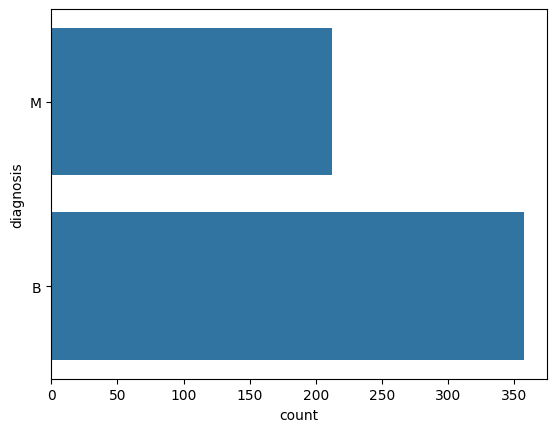

In [105]:
#Grafički prikaz malignih i benignih tumora.
sns.countplot(df['diagnosis'], label="count")

In [106]:
from sklearn.preprocessing import LabelEncoder

In [107]:
lb=LabelEncoder()

In [108]:
#Pretvaranje iz kolone diagnosis M i B da budu 1 i 0.
df.iloc[:, 0]=lb.fit_transform(df.iloc[:, 0].values)

In [109]:
#Prikaz tabele sa 1 umesto M.
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


<Axes: >

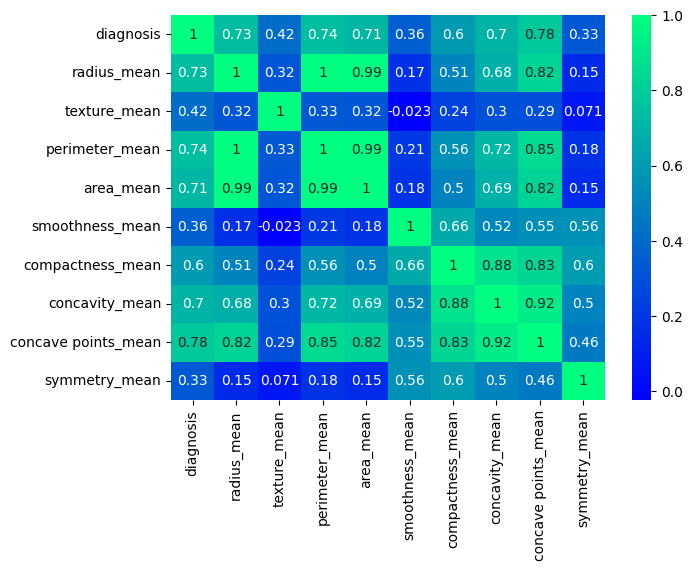

In [110]:
#Prikazivanje toplotne mape za prvih 10 kolona, koja prikazuje korelacije koeficijenata izmedju ovih kolona sa dodavanjem numeričkih vrednosti na samu mapu.
plt.figure(figsize=(7,5))
sns.heatmap(df.iloc[:, 0:10].corr(), annot=True, cmap="winter")

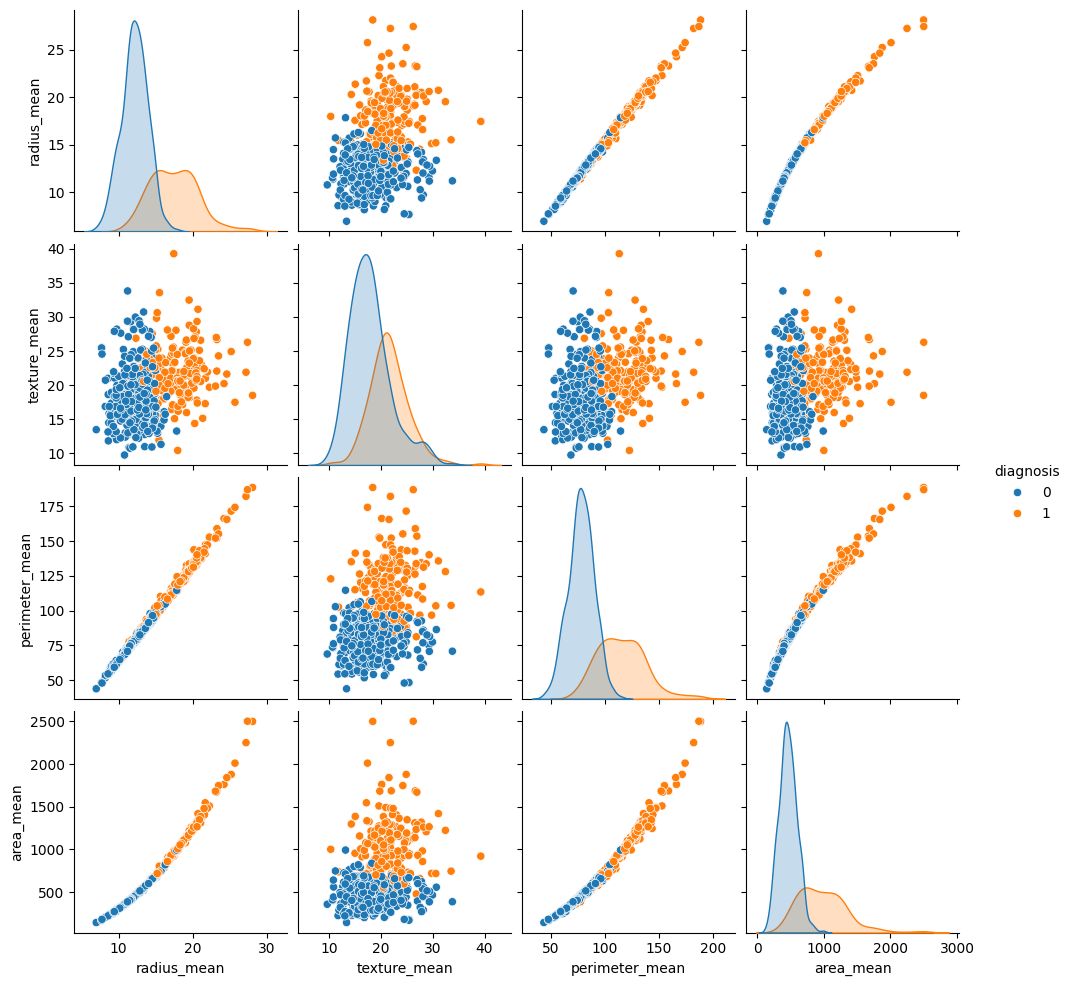

In [111]:
#Grafički prikaz kolona u osnosu na dijagnoze da li su maligni ili benigni tumori. Manigni su narandžaste tačke, benigni plave.

# radius_mean - srednja vrednost poluprečnika
# texture_mean - srednja vrednost teksture
# perimeter_mean - srednje veličine jezgra tumora

sns.pairplot(df.iloc[:, 0:5], hue="diagnosis")

<Axes: xlabel='area_mean', ylabel='area_se'>

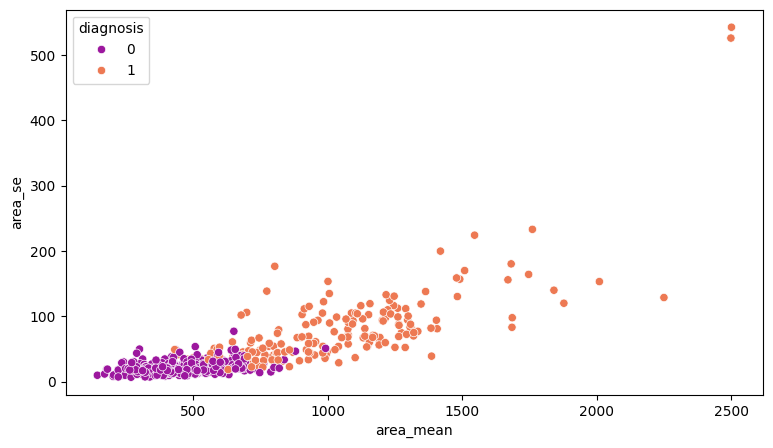

In [112]:
#Scatterplot mapa za prosečnu površinu raka dojke i greške površine raka dojke u odnosu na to koje je vrste 0/B ili 1/M.
plt.figure(figsize=(9,5))
sns.scatterplot(x=df['area_mean'], y=df['area_se'], hue=df['diagnosis'], data=df, palette="plasma")

## **Treniranje modela:**

In [113]:
#Za x se koriste kolone od 1-32, da bi se izdvojili atributi i stavljaju se u niz.
X=df.iloc[:, 1:32].values

In [114]:
X

array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]])

In [115]:
#Za y se koristi samo kolona 0, i sve se ispisuje u jedan niz.
y=df.iloc[:, 0].values

In [116]:
y

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,

In [117]:
from sklearn.model_selection import train_test_split
#0,20 koristi 20% podataka za treniranje
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2)

In [118]:
#Pretvaranje; podsetnik:LabelEncoder = lb
y_train = lb.fit_transform(y_train)
y_test = lb.transform(y_test)

In [119]:
#Transformiše podatke da svi atributi imaju srednju vrednost 0 i standardnu devijaciju 1 - kolika je razlika odstupanja
from sklearn.preprocessing import StandardScaler
st = StandardScaler()

In [120]:
#Pretvaranje
X_train = st.fit_transform(X_train)
X_test = st.transform(X_test)

## **Linearna i Logistička regresija.**


In [121]:
from sklearn.linear_model import LinearRegression, LogisticRegression

In [122]:
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report,make_scorer

In [123]:
lin = LinearRegression()

In [124]:
lin.fit(X_train, y_train)
y_pred_lin = lin.predict(X_test)
y_pred_lin_binary = (y_pred_lin > 0.5).astype(int)

In [125]:
#Rezultat treba da prikaže meru koliko dobro model radi na treniranju podataka.
lin.score(X_train, y_train)

0.7775534726414649

In [126]:
mse = mean_squared_error(y_test, y_pred_lin)

In [127]:
r2 = r2_score(y_test, y_pred_lin)

In [128]:
lin_accuracy = accuracy_score(y_test, y_pred_lin_binary)
print(f'Linearna regresija tačnost: {lin_accuracy:.2f}')
print('Linearna regresija izveštaj o klasifikaciji:')
print(classification_report(y_test, y_pred_lin_binary))

Linearna regresija tačnost: 0.96
Linearna regresija izveštaj o klasifikaciji:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        76
           1       1.00      0.87      0.93        38

    accuracy                           0.96       114
   macro avg       0.97      0.93      0.95       114
weighted avg       0.96      0.96      0.96       114



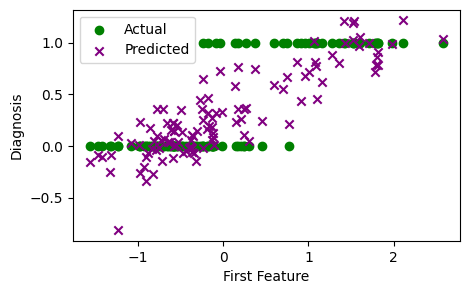

In [129]:
#Scatter plot prikazuje koliko dobro model predviđa stvarne diagnoze.
plt.figure(figsize=(5, 3))
plt.scatter(X_test[:, 0], y_test, color='green', label='Actual')
plt.scatter(X_test[:, 0], y_pred_lin, color='purple', marker='x', label='Predicted')
plt.xlabel('First Feature')
plt.ylabel('Diagnosis')
plt.legend()
plt.show()

In [130]:
X=df.iloc[:, 1:32].values
X
y=df.iloc[:, 0].values
y

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,

In [131]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Pretvaranje kolone 'diagnosis' u 0 i 1
lb = LabelEncoder()
y = lb.fit_transform(df['diagnosis'].values)  # y je 1D array: 0 = B, 1 = M
X = df.iloc[:, 1:].values  # sve ostale kolone osim 'diagnosis'

print(type(y))   # treba da bude <class 'numpy.ndarray'>
print(y.shape)   # (n_samples,)
print(np.unique(y))  # [0 1]


<class 'numpy.ndarray'>
(569,)
[0 1]


In [132]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score
import numpy as np

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Helper funkcija za evaluaciju LinearRegression-a
def evaluate_linreg(X, y):
    accuracies, f1s, recalls, precisions = [], [], [], []
    lin = LinearRegression()
    for train_idx, test_idx in skf.split(X, y):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        lin.fit(X_train, y_train)
        y_pred = (lin.predict(X_test) > 0.5).astype(int)  # binarizacija

        accuracies.append(accuracy_score(y_test, y_pred))
        f1s.append(f1_score(y_test, y_pred))
        recalls.append(recall_score(y_test, y_pred))
        precisions.append(precision_score(y_test, y_pred))
    return np.mean(accuracies), np.std(accuracies), np.mean(f1s), np.std(f1s), \
           np.mean(recalls), np.std(recalls), np.mean(precisions), np.std(precisions)

# Helper funkcija za evaluaciju klasifikatora sa cross_val_score
def evaluate_classifier(clf, X, y):
    accuracies, f1s, recalls, precisions = [], [], [], []
    for train_idx, test_idx in skf.split(X, y):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        accuracies.append(accuracy_score(y_test, y_pred))
        f1s.append(f1_score(y_test, y_pred))
        recalls.append(recall_score(y_test, y_pred))
        precisions.append(precision_score(y_test, y_pred))
    return np.mean(accuracies), np.std(accuracies), np.mean(f1s), np.std(f1s), \
           np.mean(recalls), np.std(recalls), np.mean(precisions), np.std(precisions)

# ------------------- Linear Regression -------------------
lin_metrics = evaluate_linreg(X, y)
print("Linear Regression")
print("Accuracy: %.3f ± %.3f" % (lin_metrics[0], lin_metrics[1]))
print("F1: %.3f ± %.3f" % (lin_metrics[2], lin_metrics[3]))
print("Recall: %.3f ± %.3f" % (lin_metrics[4], lin_metrics[5]))
print("Precision: %.3f ± %.3f\n" % (lin_metrics[6], lin_metrics[7]))

# ------------------- Logistic Regression -------------------
log = LogisticRegression(max_iter=5000, random_state=42)
log_metrics = evaluate_classifier(log, X, y)
print("Logistic Regression")
print("Accuracy: %.3f ± %.3f" % (log_metrics[0], log_metrics[1]))
print("F1: %.3f ± %.3f" % (log_metrics[2], log_metrics[3]))
print("Recall: %.3f ± %.3f" % (log_metrics[4], log_metrics[5]))
print("Precision: %.3f ± %.3f\n" % (log_metrics[6], log_metrics[7]))

# ------------------- Random Forest -------------------
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_metrics = evaluate_classifier(rf, X, y)
print("Random Forest")
print("Accuracy: %.3f ± %.3f" % (rf_metrics[0], rf_metrics[1]))
print("F1: %.3f ± %.3f" % (rf_metrics[2], rf_metrics[3]))
print("Recall: %.3f ± %.3f" % (rf_metrics[4], rf_metrics[5]))
print("Precision: %.3f ± %.3f\n" % (rf_metrics[6], rf_metrics[7]))


Linear Regression
Accuracy: 0.960 ± 0.025
F1: 0.941 ± 0.038
Recall: 0.896 ± 0.064
Precision: 0.995 ± 0.016

Logistic Regression
Accuracy: 0.949 ± 0.030
F1: 0.929 ± 0.046
Recall: 0.910 ± 0.081
Precision: 0.954 ± 0.046

Random Forest
Accuracy: 0.956 ± 0.024
F1: 0.940 ± 0.035
Recall: 0.934 ± 0.061
Precision: 0.949 ± 0.035



In [133]:
import pandas as pd

# Направи речник са резултатима
results = {
    "Model": ["Linear Regression", "Logistic Regression", "Random Forest"],
    "Accuracy": ["%.3f ± %.3f" % (lin_metrics[0], lin_metrics[1]),
                 "%.3f ± %.3f" % (log_metrics[0], log_metrics[1]),
                 "%.3f ± %.3f" % (rf_metrics[0], rf_metrics[1])],
    "F1": ["%.3f ± %.3f" % (lin_metrics[2], lin_metrics[3]),
           "%.3f ± %.3f" % (log_metrics[2], log_metrics[3]),
           "%.3f ± %.3f" % (rf_metrics[2], rf_metrics[3])],
    "Recall": ["%.3f ± %.3f" % (lin_metrics[4], lin_metrics[5]),
               "%.3f ± %.3f" % (log_metrics[4], log_metrics[5]),
               "%.3f ± %.3f" % (rf_metrics[4], rf_metrics[5])],
    "Precision": ["%.3f ± %.3f" % (lin_metrics[6], lin_metrics[7]),
                  "%.3f ± %.3f" % (log_metrics[6], log_metrics[7]),
                  "%.3f ± %.3f" % (rf_metrics[6], rf_metrics[7])]
}

# Направи DataFrame
df_results = pd.DataFrame(results)

# Испиши табелу
print(df_results)


                 Model       Accuracy             F1         Recall  \
0    Linear Regression  0.960 ± 0.025  0.941 ± 0.038  0.896 ± 0.064   
1  Logistic Regression  0.949 ± 0.030  0.929 ± 0.046  0.910 ± 0.081   
2        Random Forest  0.956 ± 0.024  0.940 ± 0.035  0.934 ± 0.061   

       Precision  
0  0.995 ± 0.016  
1  0.954 ± 0.046  
2  0.949 ± 0.035  


In [134]:
log = LogisticRegression()

In [135]:
log.fit(X_train, y_train)

LogisticRegression()

In [136]:
import time
start_time = time.time()
log.fit(X_train, y_train)
end_time = time.time()
print("Vreme treniranja LogisticRegression: {:.2f} sekundi".format(end_time - start_time))

Vreme treniranja LogisticRegression: 0.02 sekundi


In [137]:
y_pred_log = log.predict(X_test)

In [138]:
log.score(X_train, y_train)

0.9868131868131869

In [139]:
log_accuracy = log.score(X_test, y_test)
print(f'Logistička regresija tačnost na test skupu: {log_accuracy:.2f}')

Logistička regresija tačnost na test skupu: 0.99


In [149]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))

scoring = {'accuracy': make_scorer(accuracy_score),
           'f1': make_scorer(f1_score),
           'recall': make_scorer(recall_score),
           'precision': make_scorer(precision_score)}

scores = cross_val_score(log, X, y, cv=skf, scoring='accuracy')
print("Logistic Regression Accuracy: %.3f ± %.3f" % (scores.mean(), scores.std()))


Logistic Regression Accuracy: 0.975 ± 0.020


Zaključak 1.

Između ove dve regresije, zaključeno je da je bolja linearna regresija za predviđanje vrednosti. Ali u slučaju ovog projekta zaključeno je da je logistička regresija bolja jer se ona uglavnom više koristi za predviđanje vrednosti koje su klasifikacione(primer: maligni i benigni tumor), više je preciznija što se da primetiti i prema rezultatu koji je jako blizu 1.

## **Forest regresija.**


In [141]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [142]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f'Random Forest tačnost: {rf_accuracy:.2f}')
print('Random Forest izveštaj o klasifikaciji:')
print(classification_report(y_test, y_pred_rf))

Random Forest tačnost: 0.96
Random Forest izveštaj o klasifikaciji:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        76
           1       0.95      0.95      0.95        38

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



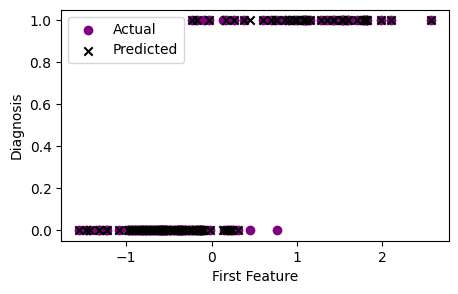

In [143]:
# Vizualizacija predikcija Random Forest modela
plt.figure(figsize=(5, 3))
plt.scatter(X_test[:, 0], y_test, color='purple', label='Actual')
plt.scatter(X_test[:, 0], y_pred_rf, color='black', marker='x', label='Predicted')
plt.xlabel('First Feature')
plt.ylabel('Diagnosis')
plt.legend()
plt.show()

In [144]:
start_time = time.time()
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
end_time = time.time()
print("Vreme treniranja RandomForest: {:.2f} sekundi".format(end_time - start_time))

Vreme treniranja RandomForest: 0.31 sekundi


In [145]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)

scores_rf = cross_val_score(rf, X, y, cv=skf, scoring='accuracy')
print("Random Forest Accuracy: %.3f ± %.3f" % (scores_rf.mean(), scores_rf.std()))


Random Forest Accuracy: 0.956 ± 0.024


## **Accuracy score i classification report.**

In [146]:
log.fit(X_train, y_train)
accuracy_score(y_test, log.predict(X_test))

0.9912280701754386

In [147]:
import pandas as pd
import numpy as np

# Пример: резултати (треба заменити својим)
results = {
    'Model': ['Linear Regression', 'Logistic Regression', 'Random Forest'],
    'Accuracy': ['0.92 ± 0.03', '0.96 ± 0.02', '0.97 ± 0.01'],
    'F1': ['0.91 ± 0.04', '0.95 ± 0.02', '0.97 ± 0.01'],
    'Recall': ['0.90 ± 0.05', '0.96 ± 0.03', '0.97 ± 0.02'],
    'Precision': ['0.93 ± 0.03', '0.95 ± 0.02', '0.97 ± 0.01']
}

df_results = pd.DataFrame(results)
print(df_results)


                 Model     Accuracy           F1       Recall    Precision
0    Linear Regression  0.92 ± 0.03  0.91 ± 0.04  0.90 ± 0.05  0.93 ± 0.03
1  Logistic Regression  0.96 ± 0.02  0.95 ± 0.02  0.96 ± 0.03  0.95 ± 0.02
2        Random Forest  0.97 ± 0.01  0.97 ± 0.01  0.97 ± 0.02  0.97 ± 0.01


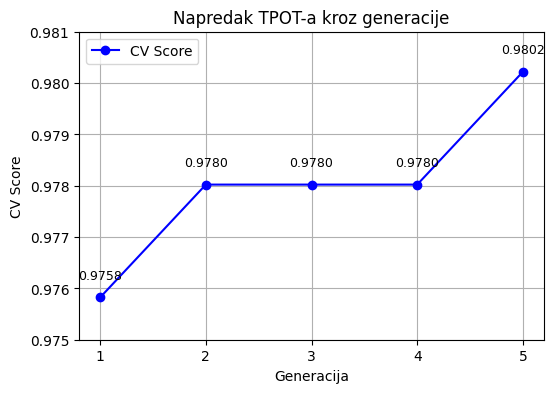

In [148]:
import matplotlib.pyplot as plt
import os

# Generacije
generations = [1, 2, 3, 4, 5]

# CV score po generaciji (iz tvojih rezultata)
cv_scores = [
    0.9758241758241759,
    0.9780219780219781,
    0.9780219780219781,
    0.9780219780219781,
    0.9802197802197803
]

plt.figure(figsize=(6, 4))
plt.plot(generations, cv_scores, marker='o', linestyle='-', color='blue', label="CV Score")
for gen, score in zip(generations, cv_scores):
    plt.text(gen, score+0.0003, f"{score:.4f}", ha='center', va='bottom', fontsize=9)

plt.xticks(generations)
plt.ylim(0.975, 0.981)  # prilagodjeno opsegu da se vidi linija
plt.xlabel("Generacija")
plt.ylabel("CV Score")
plt.title("Napredak TPOT-a kroz generacije")
plt.grid(True)
plt.legend()
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/TPOT_Generations_CV.png")
plt.show()
